In [1]:
import pandas as pd

# 1. 정제된 CSV 파일 로드 (원하시는 파일 경로로 변경 가능합니다)
file_path = 'data/processed/diabetes_binary_health_indicators_cleaned.csv'
df = pd.read_csv(file_path)

# 2. 전체 행/열 크기 및 컬럼(항목) 목록 출력
print(f"📌 데이터 크기 (행, 열): {df.shape}")
print(f"📌 전체 항목(컬럼) 목록:\n{list(df.columns)}\n")

# 3. 각 항목별 결측치(빈칸) 및 데이터 타입 상세 요약 정보
print("="*50)
print("📊 데이터프레임 상세 정보 (info):")
print("="*50)
df.info()

📌 데이터 크기 (행, 열): (252812, 22)
📌 전체 항목(컬럼) 목록:
['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']

📊 데이터프레임 상세 정보 (info):
<class 'pandas.DataFrame'>
RangeIndex: 252812 entries, 0 to 252811
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       252812 non-null  float64
 1   HighBP                252812 non-null  float64
 2   HighChol              252812 non-null  float64
 3   CholCheck             252812 non-null  float64
 4   BMI                   252812 non-null  float64
 5   Smoker                252812 non-null  float64
 6   Stroke                252812 non-null  float64
 7   HeartDiseaseorAttack  252812 non-null  float64
 8   PhysActivity          252

In [2]:
import pandas as pd

# 출력 행/열 제한 해제
pd.set_option('display.max_rows', None)     # 행 생략 해제
pd.set_option('display.max_columns', None)  # 열 생략 해제

# 이후에 df.info()나 df를 출력하면 생략 없이 모두 보입니다!
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 252812 entries, 0 to 252811
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       252812 non-null  float64
 1   HighBP                252812 non-null  float64
 2   HighChol              252812 non-null  float64
 3   CholCheck             252812 non-null  float64
 4   BMI                   252812 non-null  float64
 5   Smoker                252812 non-null  float64
 6   Stroke                252812 non-null  float64
 7   HeartDiseaseorAttack  252812 non-null  float64
 8   PhysActivity          252812 non-null  float64
 9   Fruits                252812 non-null  float64
 10  Veggies               252812 non-null  float64
 11  HvyAlcoholConsump     252812 non-null  float64
 12  AnyHealthcare         252812 non-null  float64
 13  NoDocbcCost           252812 non-null  float64
 14  GenHlth               252812 non-null  float64
 15  MentHlth   

## [결측치 점검] 결측치 없음을 확인

In [3]:
import pandas as pd

# 1. 정제된 데이터 로드
file_path = 'data/processed/diabetes_binary_health_indicators_cleaned.csv'
df = pd.read_csv(file_path)

print(f"📌 전체 데이터 행 수: {len(df):,}개, 컬럼 수: {df.shape[1]}개\n")
print("="*60)
print(f"{'#':<3} | {'Column Name':<22} | {'Outlier Count':<13} | {'Status'}")
print("="*60)

# 2. BRFSS 주요 변수별 정상 범위 정의 (도메인 기준)
# 대부분 이진 변수(0 또는 1)이거나 특정 범주형/연속형 범위를 가집니다.
def_ranges = {
    'Diabetes_binary': [0, 1],
    'HighBP': [0, 1],
    'HighChol': [0, 1],
    'CholCheck': [0, 1],
    'BMI': (10, 100),       # BMI 현실적인 의학적 범위 (예시)
    'Smoker': [0, 1],
    'Stroke': [0, 1],
    'HeartDiseaseorAttack': [0, 1],
    'PhysActivity': [0, 1],
    'Fruits': [0, 1],
    'Veggies': [0, 1],
    'HvyAlcoholConsump': [0, 1],
    'AnyHealthcare': [0, 1],
    'NoDocbcCost': [0, 1],
    'GenHlth': [1, 2, 3, 4, 5],     # 1~5점 척도
    'MentHlth': (0, 30),            # 최근 30일 기준 일수
    'PhysHlth': (0, 30),            # 최근 30일 기준 일수
    'DiffWalk': [0, 1],
    'Sex': [0, 1],
    'Age': list(range(1, 14)),      # 1~13 그룹
    'Education': list(range(1, 7)), # 1~6 그룹 (설문 코드 기준)
    'Income': list(range(1, 9))     # 1~8 그룹 (설문 코드 기준)
}

total_outliers = 0

# 3. 각 컬럼별 이상치 검사 수행
for idx, col in enumerate(df.columns):
    if col not in def_ranges:
        print(f"{idx:<3} | {col:<22} | 정의된 범위 없음  | -")
        continue
        
    rule = def_ranges[col]
    
    # 이진/범주형 검사 (리스트 형태)
    if isinstance(rule, list):
        outlier_count = ~df[col].isin(rule)
        count = outlier_count.sum()
        
    # 연속/일수형 검사 (튜플 형태: (최소, 최대))
    elif isinstance(rule, tuple):
        min_v, max_v = rule
        count = ((df[col] < min_v) | (df[col] > max_v)).sum()
        
    total_outliers += count
    status = "⚠️ 이상치 존재" if count > 0 else "정상"
    print(f"{idx:<3} | {col:<22} | {count:,}개{' ' * (10 - len(str(count)))} | {status}")

print("="*60)
print(f"✨ 총 이상치 검사 완료 (전체 발견된 이상치 합계: {total_outliers:,}개)")

📌 전체 데이터 행 수: 252,812개, 컬럼 수: 22개

#   | Column Name            | Outlier Count | Status
0   | Diabetes_binary        | 0개          | 정상
1   | HighBP                 | 0개          | 정상
2   | HighChol               | 0개          | 정상
3   | CholCheck              | 0개          | 정상
4   | BMI                    | 0개          | 정상
5   | Smoker                 | 0개          | 정상
6   | Stroke                 | 0개          | 정상
7   | HeartDiseaseorAttack   | 0개          | 정상
8   | PhysActivity           | 0개          | 정상
9   | Fruits                 | 0개          | 정상
10  | Veggies                | 0개          | 정상
11  | HvyAlcoholConsump      | 0개          | 정상
12  | AnyHealthcare          | 0개          | 정상
13  | NoDocbcCost            | 0개          | 정상
14  | GenHlth                | 0개          | 정상
15  | MentHlth               | 0개          | 정상
16  | PhysHlth               | 0개          | 정상
17  | DiffWalk               | 0개          | 정상
18  | Sex                    | 0개          | 정상

## [이상치 점검] 22개 항목에서 이상치 없음을 확인

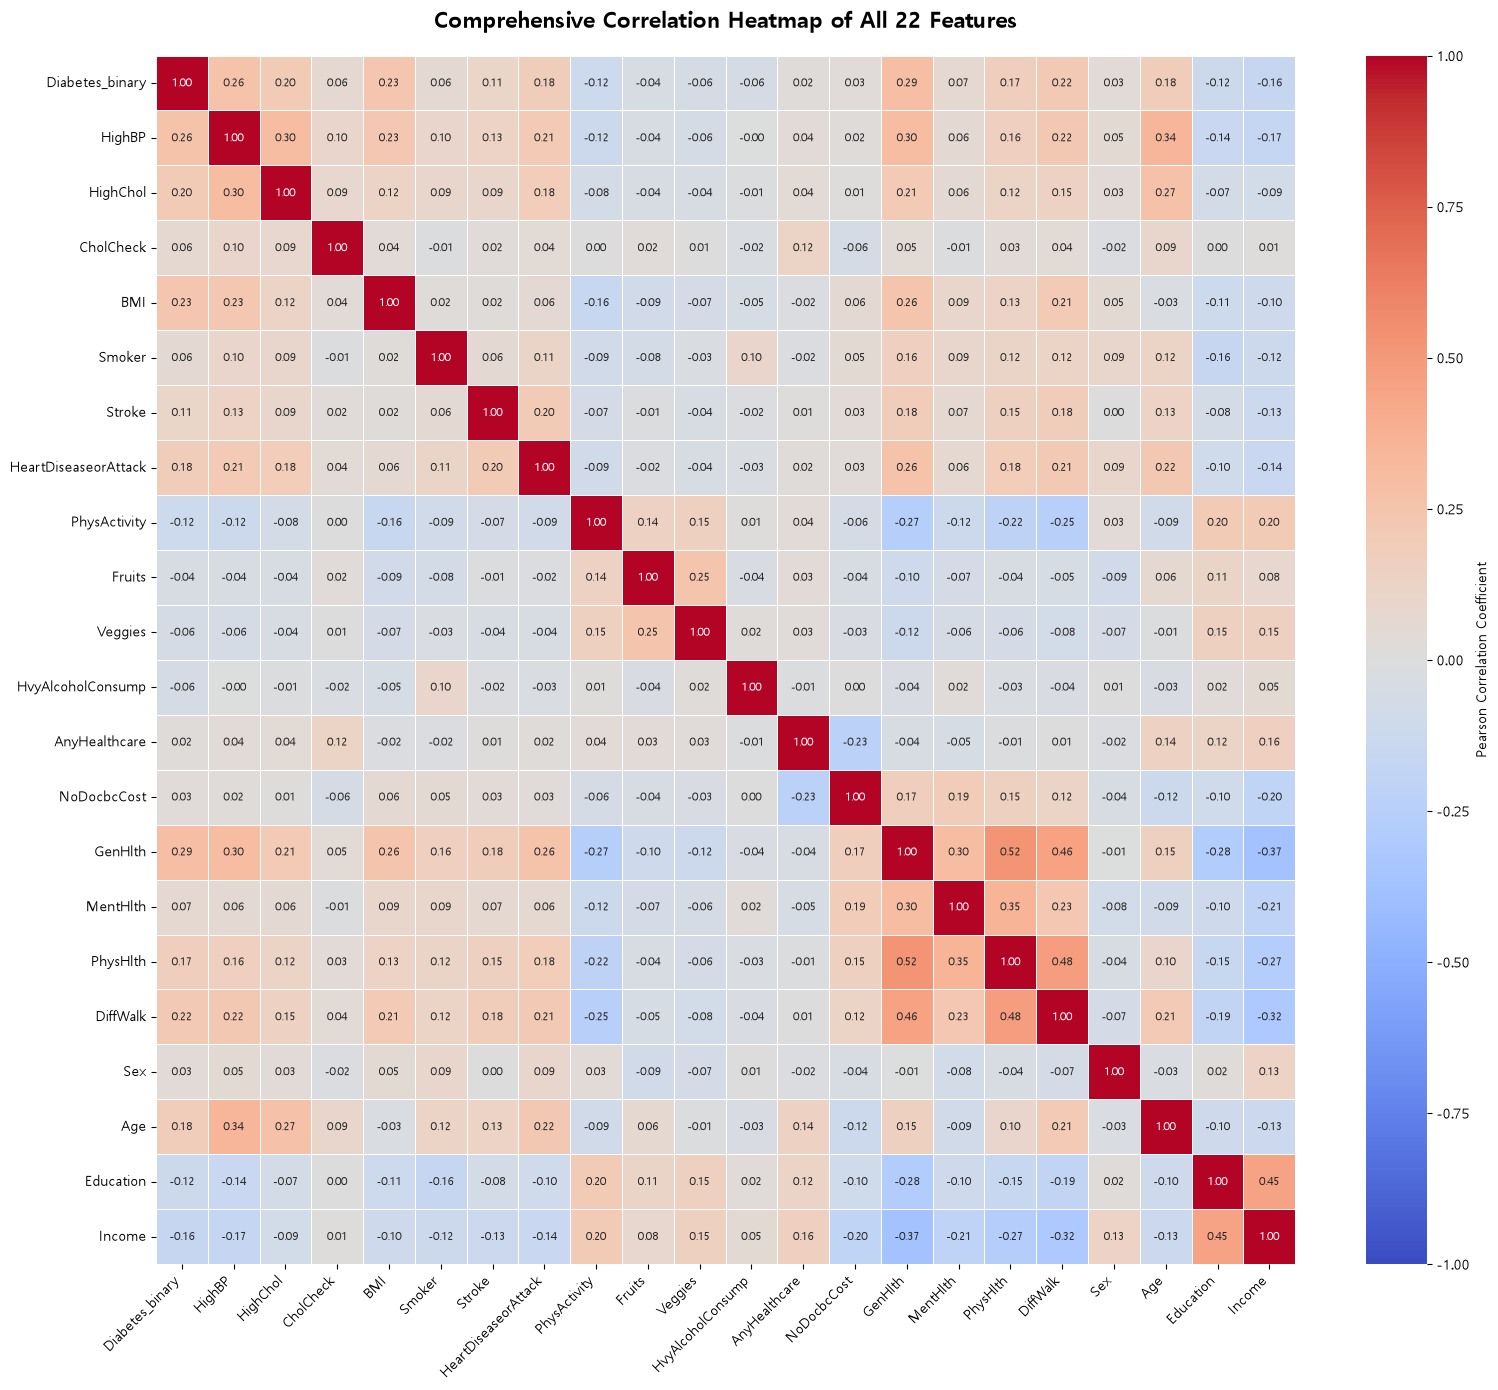

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정 (환경에 맞게 조정)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 1. 정제된 데이터 로드
file_path = 'data/processed/diabetes_binary_health_indicators_cleaned.csv'
df = pd.read_csv(file_path)

# 2. 전체 22개 컬럼에 대한 피어슨 상관계수 행렬 계산
corr_matrix = df.corr(method='pearson')

# 3. 히트맵 시각화 (22개 변수가 모두 잘 보이도록 넉넉한 도화지 크기 설정)
plt.figure(figsize=(16, 14))

# 4. seaborn heatmap 그리기
sns.heatmap(
    corr_matrix, 
    annot=True,          # 칸 안에 상관계수 숫자 표시 여부
    fmt='.2f',           # 소수점 둘째 자리까지 표시
    cmap='coolwarm',     # 색상 팔레트 (파란색: 음의 상관, 붉은색: 양의 상관)
    vmin=-1, 
    vmax=1, 
    linewidths=0.5,      # 칸 사이의 간격 선 두께
    cbar_kws={'label': 'Pearson Correlation Coefficient'},
    annot_kws={'size': 8} # 글씨가 겹치지 않도록 숫자 크기 조절
)

# 5. 그래프 제목 및 레이아웃 설정
plt.title('Comprehensive Correlation Heatmap of All 22 Features', fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)

plt.tight_layout()
plt.show()

## [섹션 8  당뇨병 예측 데이터 전체 피처 EDA 및 상관관계 분석 리포트

1. 당뇨병(Diabetes_binary)과의 주요 연관성 분석가장 강력한 영향 요인:GenHlth (일반 건강 상태, 0.29): 전반적인 체감 건강이 나쁠수록 당뇨병 발병 위험이 가장 뚜렷하게 증가함.   HighBP (고혈압, 0.26) & BMI (체질량지수, 0.23) & HighChol (고콜레스테롤, 0.20): 대사증후군 핵심 지표들이 당뇨 예측에 지대한 영향을 미침.   Age (연령대, 0.18): 나이가 많을수록 당뇨 유병률이 상승하는 전통적인 역학적 특성 반영.   사회경제적 요인의 반비례 관계:Education (-0.12) & Income (-0.16): 교육 및 소득 수준이 높을수록 당뇨 위험도가 낮아지는 사회경제적 건강 불평등(SES) 패턴 확인.  

2. 주요 다중공선성 및 변수 간 상호작용 진단고도 상관 쌍 (Multicollinearity Risk):GenHlth & PhysHlth (0.52): 체감 건강 상태와 신체 건강 악화 일수 간에 매우 강한 중복 정보 존재.   Education & Income (0.45): 교육 수준과 소득 간의 뚜렷한 양(+)의 상관관계.   HighBP & Age (0.34) / HighChol & HighBP (0.30): 연령 증가에 따른 만성질환 동반 상승 경향.   

3. 머신러닝 모델링 시사점 (Action Plan)선형 모델(로지스틱 회귀 등) 적용 시: GenHlth와 PhysHlth 간의 공선성으로 인한 계수 왜곡을 방지하기 위해 릿지(Ridge) 또는 라스소(Lasso) 규제 필수 도입.트리 기반 모델(Random Forest, XGBoost 등) 병행: 다중공선성에 강건한 트리 모델을 함께 활용하여 변수 중요도(Feature Importance)를 교차 검증하고 예측력 극대화.

In [9]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 및 마이너스 기호 설정
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 1. 저장할 디렉토리 경로 설정 및 생성 (data/interim/part1/sec8)
sec8_dir = 'data/interim/part1/sec8'
os.makedirs(sec8_dir, exist_ok=True)

# 2. 정제된 데이터 로드 (경로가 다를 경우 조정하세요)
file_path = 'data/processed/diabetes_binary_health_indicators_cleaned.csv'
if os.path.exists(file_path):
    df = pd.read_csv(file_path)
    
    # 3. 전체 22개 항목 피어슨 상관계수 행렬 계산
    corr_matrix = df.corr(method='pearson')

    # 4. 종합 히트맵 시각화 및 도표 저장
    plt.figure(figsize=(16, 14))
    sns.heatmap(
        corr_matrix, 
        annot=True,          
        fmt='.2f',           
        cmap='coolwarm',     
        vmin=-1, 
        vmax=1, 
        linewidths=0.5,      
        cbar_kws={'label': 'Pearson Correlation Coefficient'},
        annot_kws={'size': 8}
    )
    plt.title('Comprehensive Correlation Heatmap of All 22 Features (Sec 8)', fontsize=16, fontweight='bold', pad=20)
    plt.xticks(rotation=45, ha='right', fontsize=10)
    plt.yticks(fontsize=10)
    plt.tight_layout()

    # 도표를 sec8 폴더에 이미지로 저장
    chart_path = os.path.join(sec8_dir, 'comprehensive_correlation_heatmap.png')
    plt.savefig(chart_path, dpi=300)
    plt.close()
    print(f"📊 히트맵 도표 저장 완료: {chart_path}")

# 5. 마크다운 분석 리포트 작성 및 저장
sec8_report = """# Section 8: 전체 22개 피처 종합 상관관계 및 다중공선성 분석 리포트

## 1. 당뇨병(`Diabetes_binary`) 주요 연관 변수
- **최상위 영향 요인:** `GenHlth` (일반 건강 상태, 0.29), `HighBP` (고혈압, 0.26), `BMI` (체질량지수, 0.23), `HighChol` (고콜레스테롤, 0.20), `Age` (연령, 0.18)[cite: 5]
- **사회경제적 역학 관계:** `Income` (-0.16) 및 `Education` (-0.12)은 당뇨 발병률과 뚜렷한 음(-)의 상관관계를 보여 사회경제적 지위(SES)가 건강에 미치는 영향 확인[cite: 5]

## 2. 주요 다중공선성(Multicollinearity) 진단
- **고도 상관 쌍:**
  - `GenHlth` & `PhysHlth` (상관계수 0.52): 체감 일반 건강과 신체 건강 악화 일수 간 강한 중복 정보[cite: 5]
  - `Education` & `Income` (상관계수 0.45): 교육 수준과 소득 간의 뚜렷한 양(+)의 상관관계[cite: 5]
  - `HighBP` & `Age` (0.34) / `HighChol` & `HighBP` (0.30): 연령 증가에 따른 만성질환 동반 상승 패턴[cite: 5]

## 3. 머신러닝 모델링 전략 (Action Plan)
- 선형 분류 모델(로지스틱 회귀 등) 적용 시 공선성으로 인한 계수 왜곡 방지를 위해 **릿지(Ridge) 또는 라스소(Lasso) 규제** 필수 적용
- 다중공선성에 강건한 트리 기반 모델(Random Forest, XGBoost 등)을 함께 도입하여 변수 중요도(`Feature Importance`) 교차 검증 수행
"""

report_path = os.path.join(sec8_dir, 'sec8_insights_report.md')
with open(report_path, 'w', encoding='utf-8') as f:
    f.write(sec8_report)
print(f"📝 마크다운 리포트 저장 완료: {report_path}")

print(f"\n✨ [Sec 8] 모든 산출물이 성공적으로 '{sec8_dir}' 폴더에 적재되었습니다!")

📊 히트맵 도표 저장 완료: data/interim/part1/sec8\comprehensive_correlation_heatmap.png
📝 마크다운 리포트 저장 완료: data/interim/part1/sec8\sec8_insights_report.md

✨ [Sec 8] 모든 산출물이 성공적으로 'data/interim/part1/sec8' 폴더에 적재되었습니다!


In [3]:
import os
print("현재 작업 폴더:", os.getcwd())

현재 작업 폴더: c:\Users\USER\Documents\ai-campus-project\notebooks


In [5]:
import os
import pandas as pd

# 상위 폴더(../)로 나가서 data/processed 경로의 파일을 정확히 로드
input_file_path = '../data/processed/diabetes_binary_health_indicators_cleaned.csv'
df = pd.read_csv(input_file_path)

print(f"📌 processed 데이터 로드 완료. 데이터 크기 (행, 열): {df.shape}")

# BMI 바이닝(Binning) 구간 및 라벨 정의
bins = [0, 18.5, 25.0, 30.0, 100.0]
labels = ['Underweight', 'Normal', 'Overweight', 'Obese']

df['BMI_Group'] = pd.cut(df['BMI'], bins=bins, labels=labels, right=True)

# 결과 저장 경로 역시 상위 폴더 기준('../data/processed')으로 지정
output_dir = '../data/processed'
os.makedirs(output_dir, exist_ok=True)

output_file_path = os.path.join(output_dir, 'diabetes_binary_with_bmi_group.csv')
df.to_csv(output_file_path, index=False)

print(f"\n💾 피처 엔지니어링이 완료된 데이터셋이 성공적으로 저장되었습니다!")
print(f"📁 저장 경로: {output_file_path}")

📌 processed 데이터 로드 완료. 데이터 크기 (행, 열): (252812, 22)

💾 피처 엔지니어링이 완료된 데이터셋이 성공적으로 저장되었습니다!
📁 저장 경로: ../data/processed\diabetes_binary_with_bmi_group.csv


In [1]:
import os
import pandas as pd

# 1. 이전 단계에서 저장된 가공 데이터 로드 (상대 경로 ../ 적용)
input_file_path = '../data/processed/diabetes_binary_with_bmi_group.csv'
df = pd.read_csv(input_file_path)

print(f"📌 데이터 로드 완료. 데이터 크기 (행, 열): {df.shape}")
print("🔍 컬럼 목록 확인:", df.columns.tolist())

# 2. 연령(Age) 변수 확인 및 구간화 설정
# BRFSS 데이터셋의 Age는 보통 1~13 또는 연령대 코드로 되어 있거나 실제 나이일 수 있습니다.
# 데이터의 Age 값 범위를 먼저 확인해봅니다.
print("\n📊 Age 값 범위 확인:")
print(df['Age'].describe())

# 만약 Age가 1~13 형태의 연령대 코드라면(예: 1: 18~24세, 9: 60~64세 등), 
# 혹은 실제 나이(예: 20세~100세)라면 기준에 맞게 구간을 설정할 수 있습니다.
# 여기서는 일반적인 실제 나이 또는 구간 코드에 유연하게 대응할 수 있도록 예시를 구성했습니다.
# (만약 BRFSS 표준 연령 코드(1~13)라면 그에 맞는 bin 설정이 필요하므로, 연령 분포를 먼저 확인해보세요!)

# 예시: 실제 나이(Years) 기준 구간화인 경우 (필요시 수정 가능)
# bins = [0, 39, 49, 59, 69, 120]
# labels = ['Under 40', '40s', '50s', '60s', '70+')

# df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=True)

# 3. 바이닝 결과 분포 확인
# print("\n📊 연령대 그룹별 데이터 분포:")
# print(

📌 데이터 로드 완료. 데이터 크기 (행, 열): (252812, 23)
🔍 컬럼 목록 확인: ['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income', 'BMI_Group']

📊 Age 값 범위 확인:
count    252812.000000
mean          8.036466
std           3.054013
min           1.000000
25%           6.000000
50%           8.000000
75%          10.000000
max          13.000000
Name: Age, dtype: float64


In [2]:
import os
import pandas as pd

# 1. 이전 단계에서 BMI 바이닝이 완료된 CSV 파일 로드
input_file_path = '../data/processed/diabetes_binary_with_bmi_group.csv'
df = pd.read_csv(input_file_path)

print(f"📌 BMI 가공 데이터 로드 완료. 데이터 크기 (행, 열): {df.shape}")

# 2. 연령대(Age) 구간 및 라벨 정의
# BRFSS Age 코드 기준(1~13) 예시 구간 설정 (데이터 특성에 맞게 조정 가능)
bins = [0, 4, 8, 11, 13]  
labels = ['Young', 'Middle-Aged', 'Senior', 'Elderly']

# pd.cut을 이용해 연령대 구간화 수행 후 'Age_Group' 컬럼 추가
df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=True)

# 3. 연령대별 데이터 분포 확인
print("\n📊 연령대(Age_Group)별 데이터 분포:")
print(df['Age_Group'].value_counts(dropna=False))

# 4. processed 폴더 경로 설정
output_dir = '../data/processed'
os.makedirs(output_dir, exist_ok=True)

# 5. BMI와 Age 피처가 모두 포함된 통합 데이터셋으로 저장
output_file_path = os.path.join(output_dir, 'diabetes_binary_with_bmi_and_age_group.csv')
df.to_csv(output_file_path, index=False)

print(f"\n💾 BMI와 연령대(Age) 그룹이 모두 포함된 데이터셋이 성공적으로 저장되었습니다!")
print(f"📁 저장 경로: {output_file_path}")

📌 BMI 가공 데이터 로드 완료. 데이터 크기 (행, 열): (252812, 23)

📊 연령대(Age_Group)별 데이터 분포:
Age_Group
Middle-Aged    92715
Senior         88756
Young          38036
Elderly        33305
Name: count, dtype: int64

💾 BMI와 연령대(Age) 그룹이 모두 포함된 데이터셋이 성공적으로 저장되었습니다!
📁 저장 경로: ../data/processed\diabetes_binary_with_bmi_and_age_group.csv


In [3]:
import os
import pandas as pd

# 1. 이전 단계에서 BMI 바이닝이 완료된 데이터 로드
input_file_path = '../data/processed/diabetes_binary_with_bmi_group.csv'
df = pd.read_csv(input_file_path)

print(f"📌 데이터 로드 완료. 데이터 크기 (행, 열): {df.shape}")

# 2. 건강 악화 일수 구간(Bin) 및 라벨 정의
# 기준: 0일(없음), 1~14일(중간 수준), 15~30일(만성/심각)
bins = [-1, 0, 14, 30]
labels = ['None (0 days)', 'Moderate (1-14 days)', 'Severe (15-30 days)']

# PhysHlth (신체 건강 악화 일수) 구간화
df['PhysHlth_Group'] = pd.cut(df['PhysHlth'], bins=bins, labels=labels, right=True)

# MentHlth (정신 건강 악화 일수) 구간화
df['MentHlth_Group'] = pd.cut(df['MentHlth'], bins=bins, labels=labels, right=True)

# 3. 바이닝 결과 분포 확인
print("\n📊 신체 건강 악화 일수 그룹별 분포:")
print(df['PhysHlth_Group'].value_counts(dropna=False))

print("\n📊 정신 건강 악화 일수 그룹별 분포:")
print(df['MentHlth_Group'].value_counts(dropna=False))

# 4. processed 폴더 경로 설정 및 새로운 CSV 파일로 저장
output_dir = '../data/processed'
os.makedirs(output_dir, exist_ok=True)

output_file_path = os.path.join(output_dir, 'diabetes_binary_with_health_groups.csv')
df.to_csv(output_file_path, index=False)

print(f"\n💾 건강 악화 일수 바이닝이 완료된 데이터셋이 성공적으로 저장되었습니다!")
print(f"📁 저장 경로: {output_file_path}")

📌 데이터 로드 완료. 데이터 크기 (행, 열): (252812, 23)

📊 신체 건강 악화 일수 그룹별 분포:
PhysHlth_Group
None (0 days)           159608
Moderate (1-14 days)     62336
Severe (15-30 days)      30868
Name: count, dtype: int64

📊 정신 건강 악화 일수 그룹별 분포:
MentHlth_Group
None (0 days)           175163
Moderate (1-14 days)     54419
Severe (15-30 days)      23230
Name: count, dtype: int64

💾 건강 악화 일수 바이닝이 완료된 데이터셋이 성공적으로 저장되었습니다!
📁 저장 경로: ../data/processed\diabetes_binary_with_health_groups.csv


In [4]:
import os
import pandas as pd

# 1. 이전 단계에서 BMI 바이닝이 완료된 데이터 로드
input_file_path = '../data/processed/diabetes_binary_with_bmi_group.csv'
df = pd.read_csv(input_file_path)

print(f"📌 데이터 로드 완료. 데이터 크기 (행, 열): {df.shape}")

# 2. 건강 악화 일수 구간(Bin) 및 라벨 정의
# 기준: 0일(없음), 1~14일(중간 수준), 15~30일(만성/심각)
bins = [-1, 0, 14, 30]
labels = ['None (0 days)', 'Moderate (1-14 days)', 'Severe (15-30 days)']

# PhysHlth (신체 건강 악화 일수) 구간화
df['PhysHlth_Group'] = pd.cut(df['PhysHlth'], bins=bins, labels=labels, right=True)

# MentHlth (정신 건강 악화 일수) 구간화
df['MentHlth_Group'] = pd.cut(df['MentHlth'], bins=bins, labels=labels, right=True)

# 3. 바이닝 결과 분포 확인
print("\n📊 신체 건강 악화 일수 그룹별 분포:")
print(df['PhysHlth_Group'].value_counts(dropna=False))

print("\n📊 정신 건강 악화 일수 그룹별 분포:")
print(df['MentHlth_Group'].value_counts(dropna=False))

# 4. processed 폴더 경로 설정 및 새로운 CSV 파일로 저장
output_dir = '../data/processed'
os.makedirs(output_dir, exist_ok=True)

output_file_path = os.path.join(output_dir, 'diabetes_binary_with_health_groups.csv')
df.to_csv(output_file_path, index=False)

print(f"\n💾 건강 악화 일수 바이닝이 완료된 데이터셋이 성공적으로 저장되었습니다!")
print(f"📁 저장 경로: {output_file_path}")

📌 데이터 로드 완료. 데이터 크기 (행, 열): (252812, 23)

📊 신체 건강 악화 일수 그룹별 분포:
PhysHlth_Group
None (0 days)           159608
Moderate (1-14 days)     62336
Severe (15-30 days)      30868
Name: count, dtype: int64

📊 정신 건강 악화 일수 그룹별 분포:
MentHlth_Group
None (0 days)           175163
Moderate (1-14 days)     54419
Severe (15-30 days)      23230
Name: count, dtype: int64

💾 건강 악화 일수 바이닝이 완료된 데이터셋이 성공적으로 저장되었습니다!
📁 저장 경로: ../data/processed\diabetes_binary_with_health_groups.csv


In [5]:
import os
import pandas as pd

# 1. 이전 단계에서 BMI 바이닝이 완료된 데이터 로드
input_file_path = '../data/processed/diabetes_binary_with_bmi_group.csv'
df = pd.read_csv(input_file_path)

print(f"📌 데이터 로드 완료. 데이터 크기 (행, 열): {df.shape}")

# 2. 건강 악화 일수 구간(Bin) 및 라벨 정의
# 기준: 0일(없음), 1~14일(중간 수준), 15~30일(만성/심각)
bins = [-1, 0, 14, 30]
labels = ['None (0 days)', 'Moderate (1-14 days)', 'Severe (15-30 days)']

# PhysHlth (신체 건강 악화 일수) 구간화
df['PhysHlth_Group'] = pd.cut(df['PhysHlth'], bins=bins, labels=labels, right=True)

# MentHlth (정신 건강 악화 일수) 구간화
df['MentHlth_Group'] = pd.cut(df['MentHlth'], bins=bins, labels=labels, right=True)

# 3. 바이닝 결과 분포 확인
print("\n📊 신체 건강 악화 일수 그룹별 분포:")
print(df['PhysHlth_Group'].value_counts(dropna=False))

print("\n📊 정신 건강 악화 일수 그룹별 분포:")
print(df['MentHlth_Group'].value_counts(dropna=False))

# 4. processed 폴더 경로 설정 및 새로운 CSV 파일로 저장
output_dir = '../data/processed'
os.makedirs(output_dir, exist_ok=True)

output_file_path = os.path.join(output_dir, 'diabetes_binary_with_health_groups.csv')
df.to_csv(output_file_path, index=False)

print(f"\n💾 건강 악화 일수 바이닝이 완료된 데이터셋이 성공적으로 저장되었습니다!")
print(f"📁 저장 경로: {output_file_path}")

📌 데이터 로드 완료. 데이터 크기 (행, 열): (252812, 23)

📊 신체 건강 악화 일수 그룹별 분포:
PhysHlth_Group
None (0 days)           159608
Moderate (1-14 days)     62336
Severe (15-30 days)      30868
Name: count, dtype: int64

📊 정신 건강 악화 일수 그룹별 분포:
MentHlth_Group
None (0 days)           175163
Moderate (1-14 days)     54419
Severe (15-30 days)      23230
Name: count, dtype: int64

💾 건강 악화 일수 바이닝이 완료된 데이터셋이 성공적으로 저장되었습니다!
📁 저장 경로: ../data/processed\diabetes_binary_with_health_groups.csv


In [1]:
import json
import os
import pandas as pd

# 1. 기준 데이터 로드
data_path = r"C:\Users\USER\Documents\ai-campus-project\data\processed\diabetes_binary_edu_cardio_bmi_outlier_removed_binned.csv"
df = pd.read_csv(data_path)

target_col = "Diabetes_binary"
assert target_col in df.columns, f"타겟 컬럼 '{target_col}'이 데이터에 없습니다."

# 2. 파생 구간화 컬럼 및 중복 위험 원본 컬럼 정의
binned_cols = [
    c
    for c in ["BMI_Group", "MentHlth_Group", "PhysHlth_Group"]
    if c in df.columns
]
raw_binned_cols = [
    c for c in ["BMI", "MentHlth", "PhysHlth"] if c in df.columns
]

# CardioDisease로 통합된 원본 컬럼이 남아 있을 경우 중복 방지
cardio_raw_cols = [
    c
    for c in ["Stroke", "HeartDiseaseorAttack"]
    if c in df.columns and "CardioDisease" in df.columns
]

# 3. 용도별 피처 셋 분리
# (A) 2단계 수치형 상관관계 히트맵/분석용: 구간화 범주형 컬럼 제외, 숫자형 피처만 선택
numeric_corr_cols = [
    c
    for c in df.columns
    if c not in ([target_col] + binned_cols + cardio_raw_cols)
    and pd.api.types.is_numeric_dtype(df[c])
]

# (B) 3단계 모델 학습용 [연속형 원본 유지 셋]: BMI, MentHlth, PhysHlth 유지 / *_Group 제외
model_features_continuous = [
    c for c in df.columns if c not in ([target_col] + binned_cols + cardio_raw_cols)
]

# (C) 3단계 모델 학습용 [구간화 반영 셋]: BMI_Group, MentHlth_Group, PhysHlth_Group 사용 / 연속형 원본 제외
model_features_binned = [
    c for c in df.columns if c not in ([target_col] + raw_binned_cols + cardio_raw_cols)
]

# 4. 중복 및 원본·구간화 동시 포함 여부 검증
feature_sets = {
    "numeric_corr_cols": numeric_corr_cols,
    "model_features_continuous": model_features_continuous,
    "model_features_binned": model_features_binned,
}

for set_name, cols in feature_sets.items():
    assert len(cols) == len(set(cols)), f"[{set_name}] 중복 컬럼이 존재합니다."
    assert target_col not in cols, f"[{set_name}] 타겟 컬럼이 피처 목록에 섞여 있습니다."
    for raw_c, bin_c in [
        ("BMI", "BMI_Group"),
        ("MentHlth", "MentHlth_Group"),
        ("PhysHlth", "PhysHlth_Group"),
    ]:
        assert not (
            raw_c in cols and bin_c in cols
        ), f"[{set_name}] '{raw_c}'와 '{bin_c}'가 함께 포함되어 다중공선성 위험이 있습니다."

# 5. 요약 출력 및 JSON 저장
print(f"데이터 크기: {df.shape[0]:,}행 × {df.shape[1]}열")
print(f"• 2단계 수치형 상관분석용 ({len(numeric_corr_cols)}개): {numeric_corr_cols}")
print(f"• 3단계 모델용 [연속형 유지] ({len(model_features_continuous)}개): {model_features_continuous}")
print(f"• 3단계 모델용 [구간화 반영] ({len(model_features_binned)}개): {model_features_binned}")

interim_dir = r"C:\Users\USER\Documents\ai-campus-project\data\interim"
os.makedirs(interim_dir, exist_ok=True)
registry_path = os.path.join(interim_dir, "feature_registry.json")

with open(registry_path, "w", encoding="utf-8") as f:
    json.dump(
        {
            "source_file": data_path,
            "target": target_col,
            "binned_cols": binned_cols,
            "numeric_corr_cols": numeric_corr_cols,
            "model_features_continuous": model_features_continuous,
            "model_features_binned": model_features_binned,
        },
        f,
        ensure_ascii=False,
        indent=2,
    )

print(f"\n✅ 피처 목록 저장 완료: {registry_path}")

데이터 크기: 252,812행 × 24열
• 2단계 수치형 상관분석용 (20개): ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income', 'CardioDisease']
• 3단계 모델용 [연속형 유지] (20개): ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income', 'CardioDisease']
• 3단계 모델용 [구간화 반영] (20개): ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income', 'CardioDisease', 'BMI_Group', 'MentHlth_Group', 'PhysHlth_Group']

✅ 피처 목록 저장 완료: C:\Users\USER\Documents\ai-campus-project\data\interim\feature_registry.json


In [2]:
import json

with open(
    r"C:\Users\USER\Documents\ai-campus-project\data\interim\feature_registry.json",
    "r",
    encoding="utf-8",
) as f:
    reg = json.load(f)

X_cont = df[reg["model_features_continuous"]]  # 연속형 원본 기준 피처
X_bin = df[reg["model_features_binned"]]  # 구간화 기준 피처
y = df[reg["target"]]

In [4]:
import json
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 한글 폰트 및 마이너스 기호 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 1. 피처 레지스트리 및 정제 데이터 로드
registry_path = (
    r"C:\Users\USER\Documents\ai-campus-project\data\interim\feature_registry.json"
)
with open(registry_path, "r", encoding="utf-8") as f:
    reg = json.load(f)

df = pd.read_csv(reg["source_file"])
target_col = reg["target"]
corr_cols = [target_col] + reg["numeric_corr_cols"]

# 2. 피어슨 상관계수 행렬 계산 (총 21개: 타겟 1 + 수치/서열/이진 20)
corr_matrix = df[corr_cols].corr(method="pearson")

# 3. 당뇨병(Diabetes_binary)과의 상관계수 순위 출력
target_corr = corr_matrix[target_col].drop(target_col).sort_values(ascending=False)
print("=== [1] Diabetes_binary와의 상관계수 상위/하위 변수 ===")
for col, val in target_corr.items():
    print(f"- {col:18s}: {val:+.4f}")

# 4. 변수 간 상관계수 절댓값이 0.40 이상인 전체 쌍 추출 (생략 없이 전체 출력)
threshold = 0.40
high_pairs = []
cols_list = corr_matrix.columns.tolist()
for i in range(len(cols_list)):
    for j in range(i):
        val = corr_matrix.iloc[i, j]
        if abs(val) >= threshold:
            high_pairs.append((cols_list[j], cols_list[i], val))

high_pairs.sort(key=lambda x: abs(x[2]), reverse=True)

print(f"\n=== [2] 변수 간 상관계수 |r| >= {threshold:.2f} 쌍 (총 {len(high_pairs)}쌍) ===")
if high_pairs:
    for c1, c2, val in high_pairs:
        print(f"- {c1} ↔ {c2}: {val:+.4f}")
else:
    print(f"기준치({threshold:.2f}) 이상인 변수 쌍이 없습니다.")

# 5. 저장 디렉토리 생성 (data/interim/part3)
out_dir = r"C:\Users\USER\Documents\ai-campus-project\data\interim\part3"
os.makedirs(out_dir, exist_ok=True)

# 6. 상관관계 히트맵 시각화 및 저장
plt.figure(figsize=(16, 14))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation Coefficient"},
    annot_kws={"size": 8},
)
plt.title(
    "Correlation Heatmap (Target + 20 Numeric/Ordinal/Binary Features)",
    fontsize=15,
    fontweight="bold",
    pad=18,
)
plt.xticks(rotation=45, ha="right", fontsize=9.5)
plt.yticks(fontsize=9.5)
plt.tight_layout()

heatmap_path = os.path.join(out_dir, "correlation_heatmap_21cols.png")
plt.savefig(heatmap_path, dpi=300)
plt.close()

# 7. 요약 마크다운 저장 (고도 상관 쌍 전체 기록)
summary_path = os.path.join(out_dir, "correlation_summary.md")
with open(summary_path, "w", encoding="utf-8") as f:
    f.write("# 2단계 상관관계 분석 요약\n\n")
    f.write("## 1. Diabetes_binary 상관계수 순위\n")
    for col, val in target_corr.items():
        f.write(f"- `{col}`: `{val:+.4f}`\n")
    f.write(f"\n## 2. 고도 상관 변수 쌍 (|r| >= {threshold:.2f}, 총 {len(high_pairs)}쌍)\n")
    if high_pairs:
        for c1, c2, val in high_pairs:
            f.write(f"- `{c1}` ↔ `{c2}`: `{val:+.4f}`\n")
    else:
        f.write("- 기준치 이상 변수 쌍 없음\n")

print(f"\n✅ 히트맵 저장 완료: {heatmap_path}")
print(f"✅ 요약 리포트 저장 완료: {summary_path}")

=== [1] Diabetes_binary와의 상관계수 상위/하위 변수 ===
- GenHlth           : +0.2929
- HighBP            : +0.2627
- BMI               : +0.2347
- DiffWalk          : +0.2169
- HighChol          : +0.2003
- CardioDisease     : +0.1859
- Age               : +0.1778
- PhysHlth          : +0.1701
- MentHlth          : +0.0689
- CholCheck         : +0.0647
- Smoker            : +0.0609
- Sex               : +0.0320
- NoDocbcCost       : +0.0312
- AnyHealthcare     : +0.0164
- Fruits            : -0.0406
- Veggies           : -0.0563
- HvyAlcoholConsump : -0.0569
- PhysActivity      : -0.1172
- Education         : -0.1242
- Income            : -0.1631

=== [2] 변수 간 상관계수 |r| >= 0.40 쌍 (총 4쌍) ===
- GenHlth ↔ PhysHlth: +0.5235
- PhysHlth ↔ DiffWalk: +0.4774
- GenHlth ↔ DiffWalk: +0.4556
- Education ↔ Income: +0.4494

✅ 히트맵 저장 완료: C:\Users\USER\Documents\ai-campus-project\data\interim\part3\correlation_heatmap_21cols.png
✅ 요약 리포트 저장 완료: C:\Users\USER\Documents\ai-campus-project\data\interim\part3\correlat

## 히트맵 상관관계 개괄분석

GenHlth(+0.2929), HighBP(+0.2627), BMI(+0.2347), DiffWalk(+0.2169), HighChol(+0.2003), CardioDisease(+0.1859), Age(+0.1778) 등이 상위권, 
PhysActivity(-0.1172), Education(-0.1242), Income(-0.1631)는 음의 상관관계.

이후 정제된 데이터(feature_registry.json의 source_file)를 기준으로 각 변수의 오즈비(OR), 95% 신뢰구간(CI), p-value를 계산할 예정.

In [5]:
import json
import os
import numpy as np
import pandas as pd
import statsmodels.api as sm

# 1. 피처 레지스트리 및 정제 데이터 로드
registry_path = (
    r"C:\Users\USER\Documents\ai-campus-project\data\interim\feature_registry.json"
)
with open(registry_path, "r", encoding="utf-8") as f:
    reg = json.load(f)

df = pd.read_csv(reg["source_file"])
target_col = reg["target"]
feature_cols = reg["numeric_corr_cols"]

results = []

for col in feature_cols:
  sub = df[[col, target_col]].dropna()
  y = sub[target_col]
  unique_vals = sorted(sub[col].unique())

  # 이진 변수(0/1)인 경우: 2x2 교차표 기반 오즈비 + 로지스틱 회귀 검증
  if set(unique_vals).issubset({0, 1}) and len(unique_vals) == 2:
    n11 = int(((sub[col] == 1) & (y == 1)).sum())
    n10 = int(((sub[col] == 1) & (y == 0)).sum())
    n01 = int(((sub[col] == 0) & (y == 1)).sum())
    n00 = int(((sub[col] == 0) & (y == 0)).sum())

    # 0 셀 보정(Haldane-Anscombe correction) 안전 장치
    a, b, c, d = n11, n10, n01, n00
    if 0 in (a, b, c, d):
      a, b, c, d = a + 0.5, b + 0.5, c + 0.5, d + 0.5

    or_val = (a * d) / (b * c)
    log_or = np.log(or_val)
    se_log_or = np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
    ci_low = np.exp(log_or - 1.96 * se_log_or)
    ci_high = np.exp(log_or + 1.96 * se_log_or)

    X = sm.add_constant(sub[col].astype(float))
    logit_res = sm.Logit(y, X).fit(disp=False)
    p_val = float(logit_res.pvalues.iloc[1])

    prev_1 = n11 / (n11 + n10) if (n11 + n10) > 0 else np.nan
    prev_0 = n01 / (n01 + n00) if (n01 + n00) > 0 else np.nan

    results.append({
        "feature": col,
        "var_type": "binary (1 vs 0)",
        "unit_scale": "1 unit (1 vs 0)",
        "odds_ratio": or_val,
        "ci_lower": ci_low,
        "ci_upper": ci_high,
        "p_value": p_val,
        "prev_when_1": prev_1,
        "prev_when_0": prev_0,
    })

  # 연속형 / 서열형 변수인 경우: 1단위 증가당 OR + 1 IQR(또는 1 SD) 증가당 OR 함께 산출
  else:
    x_num = sub[col].astype(float)
    X = sm.add_constant(x_num)
    logit_res = sm.Logit(y, X).fit(disp=False)

    beta = float(logit_res.params.iloc[1])
    se = float(logit_res.bse.iloc[1])
    p_val = float(logit_res.pvalues.iloc[1])

    or_1unit = np.exp(beta)
    ci_low_1 = np.exp(beta - 1.96 * se)
    ci_high_1 = np.exp(beta + 1.96 * se)

    q75, q25 = np.percentile(x_num, [75, 25])
    iqr = float(q75 - q25)
    step = iqr if iqr > 0 else float(x_num.std())
    scale_label = f"+1 IQR ({iqr:.2f})" if iqr > 0 else f"+1 SD ({step:.2f})"

    or_scaled = np.exp(beta * step)
    ci_low_s = np.exp((beta - 1.96 * se) * step)
    ci_high_s = np.exp((beta + 1.96 * se) * step)

    results.append({
        "feature": col,
        "var_type": "continuous/ordinal (1 unit)",
        "unit_scale": "1 unit (+1)",
        "odds_ratio": or_1unit,
        "ci_lower": ci_low_1,
        "ci_upper": ci_high_1,
        "p_value": p_val,
        "prev_when_1": np.nan,
        "prev_when_0": np.nan,
    })

    results.append({
        "feature": col,
        "var_type": "continuous/ordinal (scaled)",
        "unit_scale": scale_label,
        "odds_ratio": or_scaled,
        "ci_lower": ci_low_s,
        "ci_upper": ci_high_s,
        "p_value": p_val,
        "prev_when_1": np.nan,
        "prev_when_0": np.nan,
    })

or_df = pd.DataFrame(results)

# 이진 변수 & 연속/서열형(1단위) 기준으로 오즈비 내림차순 정렬 확인용 뷰
print("=== [1] 이진 변수 (1 vs 0) 오즈비 순위 ===")
bin_view = or_df[or_df["var_type"] == "binary (1 vs 0)"].sort_values(
    "odds_ratio", ascending=False
)
for _, r in bin_view.iterrows():
  p_str = "< 1e-300" if r["p_value"] == 0 else f"{r['p_value']:.2e}"
  print(
      f"- {r['feature']:18s}: OR = {r['odds_ratio']:.3f} "
      f"(95% CI: {r['ci_lower']:.3f} ~ {r['ci_upper']:.3f}), p = {p_str} "
      f"[유병률 1: {r['prev_when_1']*100:.1f}% vs 0: {r['prev_when_0']*100:.1f}%]"
  )

print("\n=== [2] 연속형·서열형 변수 (1단위 및 +1 IQR 기준) 오즈비 ===")
cont_1unit = or_df[
    or_df["var_type"] == "continuous/ordinal (1 unit)"
].sort_values("odds_ratio", ascending=False)
for _, r in cont_1unit.iterrows():
  s_row = or_df[
      (or_df["feature"] == r["feature"])
      & (or_df["var_type"] == "continuous/ordinal (scaled)")
  ].iloc[0]
  p_str = "< 1e-300" if r["p_value"] == 0 else f"{r['p_value']:.2e}"
  print(
      f"- {r['feature']:12s} | 1단위 OR: {r['odds_ratio']:.3f} "
      f"({r['ci_lower']:.3f}~{r['ci_upper']:.3f}) | "
      f"{s_row['unit_scale']} OR: {s_row['odds_ratio']:.3f} "
      f"({s_row['ci_lower']:.3f}~{s_row['ci_upper']:.3f}) | p = {p_str}"
  )

# 3. 산출물 저장 (data/interim/part3)
out_dir = r"C:\Users\USER\Documents\ai-campus-project\data\interim\part3"
os.makedirs(out_dir, exist_ok=True)

csv_path = os.path.join(out_dir, "odds_ratio_univariate.csv")
md_path = os.path.join(out_dir, "odds_ratio_summary.md")

or_df.to_csv(csv_path, index=False, encoding="utf-8-sig")

with open(md_path, "w", encoding="utf-8") as f:
  f.write("# 2단계 단변량 오즈비(Odds Ratio) 분석 요약\n\n")
  f.write("## 1. 이진 변수 (1 vs 0) 오즈비 순위\n")
  for _, r in bin_view.iterrows():
    p_str = "< 1e-300" if r["p_value"] == 0 else f"{r['p_value']:.2e}"
    f.write(
        f"- `{r['feature']}`: OR = `{r['odds_ratio']:.3f}` "
        f"(95% CI: `{r['ci_lower']:.3f} ~ {r['ci_upper']:.3f}`), "
        f"p = `{p_str}` (1일 때 `{r['prev_when_1']*100:.1f}%` vs 0일 때 `{r['prev_when_0']*100:.1f}%`)\n"
    )
  f.write("\n## 2. 연속형·서열형 변수 (1단위 및 +1 IQR 기준) 오즈비\n")
  for _, r in cont_1unit.iterrows():
    s_row = or_df[
        (or_df["feature"] == r["feature"])
        & (or_df["var_type"] == "continuous/ordinal (scaled)")
    ].iloc[0]
    p_str = "< 1e-300" if r["p_value"] == 0 else f"{r['p_value']:.2e}"
    f.write(
        f"- `{r['feature']}`: 1단위 OR = `{r['odds_ratio']:.3f}` "
        f"(`{r['ci_lower']:.3f} ~ {r['ci_upper']:.3f}`), "
        f"`{s_row['unit_scale']}` OR = `{s_row['odds_ratio']:.3f}` "
        f"(`{s_row['ci_lower']:.3f} ~ {s_row['ci_upper']:.3f}`), p = `{p_str}`\n"
    )

print(f"\n✅ CSV 저장 완료: {csv_path}")
print(f"✅ 요약 리포트 저장 완료: {md_path}")

=== [1] 이진 변수 (1 vs 0) 오즈비 순위 ===
- CholCheck         : OR = 6.422 (95% CI: 5.646 ~ 7.303), p = 1.44e-176 [유병률 1: 14.3% vs 0: 2.5%]
- HighBP            : OR = 5.030 (95% CI: 4.903 ~ 5.161), p = < 1e-300 [유병률 1: 24.4% vs 0: 6.0%]
- DiffWalk          : OR = 3.750 (95% CI: 3.657 ~ 3.844), p = < 1e-300 [유병률 1: 30.6% vs 0: 10.5%]
- CardioDisease     : OR = 3.507 (95% CI: 3.412 ~ 3.605), p = < 1e-300 [유병률 1: 31.4% vs 0: 11.5%]
- HighChol          : OR = 3.259 (95% CI: 3.182 ~ 3.337), p = < 1e-300 [유병률 1: 22.0% vs 0: 8.0%]
- Smoker            : OR = 1.421 (95% CI: 1.389 ~ 1.454), p = 1.91e-204 [유병률 1: 16.3% vs 0: 12.0%]
- NoDocbcCost       : OR = 1.347 (95% CI: 1.298 ~ 1.398), p = 4.13e-55 [유병률 1: 17.5% vs 0: 13.6%]
- AnyHealthcare     : OR = 1.268 (95% CI: 1.198 ~ 1.342), p = 2.01e-16 [유병률 1: 14.0% vs 0: 11.4%]
- Sex               : OR = 1.203 (95% CI: 1.176 ~ 1.231), p = 5.35e-58 [유병률 1: 15.1% vs 0: 12.9%]
- Fruits            : OR = 0.788 (95% CI: 0.770 ~ 0.806), p = 2.93e-92 [유병률 1: 12.8% 

## 오즈비(OR) 분석 핵심

주요 위험 요인(OR > 1): GenHlth(+1 IQR OR 2.196), HighBP(OR 5.030, 유병률 24.4% vs 6.0%), DiffWalk(OR 3.750), CardioDisease(OR 3.507), HighChol(OR 3.259), Age(+1 IQR OR 2.133), BMI(+1 IQR OR 1.981)에서 당뇨 위험 상승 경향이 뚜렷함.

보호/역방향 요인(OR < 1): PhysActivity(OR 0.492), Veggies(OR 0.681), Fruits(OR 0.788), Income(+1 IQR OR 0.538), Education(+1 IQR OR 0.506)은 당뇨 오즈가 낮아지는 방향을 보임.

고도 상관 변수 쌍(|r| >= 0.40): GenHlth ↔ PhysHlth(+0.5235), PhysHlth ↔ DiffWalk(+0.4774), GenHlth ↔ DiffWalk(+0.4556), Education ↔ Income(+0.4494) 간 중복/공선성 관리 필요.

** 확인 포인트
BMI +1 IQR = 7.00 (OR = 1.981): 등급이 아닌 연속형 BMI(12~59)의 중간 50% 분포 폭(7점) 상승 시 당뇨 오즈가 약 1.98배 커진다는 의미.

CholCheck (OR = 6.422, 유병률 14.3% vs 2.5%): 미검진군 유병률이 2.5%로 매우 낮아 OR이 크게 나오며, 검진·진단 여부에 따른 검진/역인과 편향 고려 필요.

HvyAlcoholConsump (OR = 0.369, 유병률 5.8% vs 14.4%): 설문 시점 기준 데이터이므로 진단·건강 악화 이후 절주/금주 또는 중증 환자 배제(역인과·생존 편향) 가능성 감안해 해석.

다음 단계: 위 위험 요인을 바탕으로 상호작용 피처(Interaction Feature) 후보 생성 및 유병률·오즈 비교 진행.

##  상호작용 피처(Interaction Feature) 4대 축 요약

1. 대사증후군 복합 위험 축 (`Metabolic_Risk_Count`, `Triple_Metabolic_Risk`)**

  * **구성:** `HighBP` + `HighChol` + `Is_Obese`(`BMI >= 30`) 보유 개수(`0~3점`) 및 3중 동반 플래그(`0/1`)

  * **선정 이유:** 의학적 대사증후군 정의와 단변량 상위 위험 요인(`HighBP`, `HighChol`, `BMI`)을 결합해, 개별 변수의 단순 합산만으로는 잡기 어려운 복합 시너지(위험 급등)를 선형 모델이 직접 학습하도록 설계함

  * **핵심 인사이트:** 위험 요인이 누적될수록 당뇨 유병률이 계단식으로 상승하며, 3중 동반군(`Triple_Metabolic_Risk == 1`)에서 초고위험 패턴이 집중됨

2. 연령 × 대사·건강 취약 결합 축 (`Age_HighBP_Inter`, `Aged_Poor_Health`)**

  * **구성:** `Age * HighBP` 및 `(Age >= 9) & (GenHlth >= 3)` (60세 이상 & 건강상태 '좋음' 이하)

  * **선정 이유:** 젊은 층과 고령층(`Age >= 9`)의 동일한 고혈압·건강 저하는 누적 위험도가 다르므로, 연령대와의 교차항을 통해 비선형적 위험 상승 구간을 포착함

  * **핵심 인사이트:** 연령 증가에 따른 기본 유병률 상승에 고혈압·건강 악화가 겹칠 때 당뇨 발병 오즈가 가파르게 확대됨

3. 신체기능·심혈관 누적 부담 축 (`Cardio_DiffWalk_Inter`, `GenHlth_BMI_Inter`)**

  * **구성:** `CardioDisease * DiffWalk` 및 `GenHlth * BMI`

  * **선정 이유:** 단변량 오즈비 상위권인 심혈관 질환(`CardioDisease`)과 보행 곤란(`DiffWalk`)의 동반 여부, 그리고 주관적 건강 악화(`GenHlth`)와 체중 부담(`BMI`)의 결합 효과를 반영함

  * **핵심 인사이트:** 심혈관 기왕력과 이동 제약이 동시에 나타나거나 건강 저하에 비만이 겹친 고부담 집단에서 당뇨 위험이 크게 증폭됨

4. 불건강 생활습관 누적 지수 (`Unhealthy_Lifestyle_Score`, `Metabolic_BadLife_Inter`)**

  * **구성:** `(1 - PhysActivity) + Smoker + (1 - Fruits) + (1 - Veggies)` (`0~4점`) 및 대사 고위험(`>= 2개`) × 생활습관 고위험(`>= 3점`) 교차 플래그

  * **선정 이유:** 개별 생활습관 변수는 단독 상관계수가 낮으나, 나쁜 습관이 다수 누적된 행동 리스크를 단일 지수로 요약하고 대사 질환 위험군과의 결합 효과를 검증하기 위함

  * **핵심 인사이트:** 단일 생활습관보다 복합적인 불건강 습관이 누적될 때, 특히 기저 대사 위험군과 겹칠 때 당뇨 취약성이 뚜렷해짐

In [6]:
import json
import os
import numpy as np
import pandas as pd
import statsmodels.api as sm

# 1. 피처 레지스트리 및 정제 데이터 로드
registry_path = (
    r"C:\Users\USER\Documents\ai-campus-project\data\interim\feature_registry.json"
)
with open(registry_path, "r", encoding="utf-8") as f:
    reg = json.load(f)

df = pd.read_csv(reg["source_file"])
target_col = reg["target"]

# 2. 상호작용 피처(Interaction Feature) 후보 생성
# (기준 보조 플래그: 비만 BMI >= 30, 60세 이상 Age >= 9, 주관적 건강 '좋음' 이하 GenHlth >= 3)
is_obese = (df["BMI"] >= 30).astype(int)
age_60plus = (df["Age"] >= 9).astype(int)
genhlth_risk = (df["GenHlth"] >= 3).astype(int)

# [축 1] 대사증후군 복합 위험
df["Metabolic_Risk_Count"] = df["HighBP"] + df["HighChol"] + is_obese  # 0 ~ 3점
df["Triple_Metabolic_Risk"] = (df["Metabolic_Risk_Count"] == 3).astype(int)  # 3중 보유(0/1)

# [축 2] 연령 x 대사·건강 취약 결합
df["Age_HighBP_Inter"] = df["Age"] * df["HighBP"]  # 연령 x 고혈압
df["Aged_Poor_Health"] = age_60plus * genhlth_risk  # 60세 이상 & 건강상태 저하(0/1)

# [축 3] 신체기능·심혈관 누적 부담
df["Cardio_DiffWalk_Inter"] = df["CardioDisease"] * df["DiffWalk"]  # 심혈관 & 보행곤란(0/1)
df["GenHlth_BMI_Inter"] = df["GenHlth"] * df["BMI"]  # 주관적 건강 x BMI

# [축 4] 불건강 생활습관 누적 및 대사-생활습관 결합
df["Unhealthy_Lifestyle_Score"] = (
    (1 - df["PhysActivity"])
    + df["Smoker"]
    + (1 - df["Fruits"])
    + (1 - df["Veggies"])
)  # 0 ~ 4점
df["Metabolic_BadLife_Inter"] = (
    (df["Metabolic_Risk_Count"] >= 2) & (df["Unhealthy_Lifestyle_Score"] >= 3)
).astype(int)

interaction_cols = [
    "Metabolic_Risk_Count",
    "Triple_Metabolic_Risk",
    "Age_HighBP_Inter",
    "Aged_Poor_Health",
    "Cardio_DiffWalk_Inter",
    "GenHlth_BMI_Inter",
    "Unhealthy_Lifestyle_Score",
    "Metabolic_BadLife_Inter",
]

# 3. 상호작용 피처별 상관계수, 단변량 오즈비(OR), 유병률 검증
eval_rows = []
y = df[target_col]

for col in interaction_cols:
    x = df[col].astype(float)
    corr = float(x.corr(y))

    X_logit = sm.add_constant(x)
    logit_res = sm.Logit(y, X_logit).fit(disp=False)
    beta = float(logit_res.params.iloc[1])
    se = float(logit_res.bse.iloc[1])
    p_val = float(logit_res.pvalues.iloc[1])

    or_1unit = float(np.exp(beta))
    ci_low = float(np.exp(beta - 1.96 * se))
    ci_high = float(np.exp(beta + 1.96 * se))

    unique_vals = sorted(df[col].unique())
    if set(unique_vals).issubset({0, 1}) and len(unique_vals) == 2:
        prev_1 = float(df.loc[df[col] == 1, target_col].mean())
        prev_0 = float(df.loc[df[col] == 0, target_col].mean())
        count_1 = int((df[col] == 1).sum())
        note = f"1일 때 유병률 {prev_1*100:.1f}% vs 0일 때 {prev_0*100:.1f}% (n1={count_1:,})"
    else:
        q75, q25 = np.percentile(x, [75, 25])
        iqr = float(q75 - q25)
        or_iqr = float(np.exp(beta * iqr)) if iqr > 0 else np.nan
        note = f"+1 IQR({iqr:.1f})당 OR = {or_iqr:.3f}" if iqr > 0 else "연속/점수형"

    eval_rows.append(
        {
            "feature": col,
            "corr_with_target": corr,
            "odds_ratio_1unit": or_1unit,
            "ci_lower": ci_low,
            "ci_upper": ci_high,
            "p_value": p_val,
            "detail": note,
        }
    )

eval_df = pd.DataFrame(eval_rows).sort_values("corr_with_target", ascending=False)

print("=== [1] 상호작용 피처 후보 통계 검증 결과 ===")
for _, r in eval_df.iterrows():
    p_str = "< 1e-300" if r["p_value"] == 0 else f"{r['p_value']:.2e}"
    print(
        f"- {r['feature']:26s} | r = {r['corr_with_target']:+.4f} | "
        f"1단위 OR = {r['odds_ratio_1unit']:.3f} ({r['ci_lower']:.3f}~{r['ci_upper']:.3f}) | "
        f"p = {p_str} | {r['detail']}"
    )

print("\n=== [2] 대사증후군 복합 위험 점수(Metabolic_Risk_Count) 구간별 당뇨 유병률 ===")
summary_meta = (
    df.groupby("Metabolic_Risk_Count")[target_col]
    .agg(표본수="count", 당뇨유병률=lambda s: f"{s.mean()*100:.1f}%")
)
print(summary_meta)

# 4. 파생변수 포함 데이터셋 저장 및 feature_registry 업데이트
out_dir = r"C:\Users\USER\Documents\ai-campus-project\data\interim\part3"
os.makedirs(out_dir, exist_ok=True)

inter_data_path = os.path.join(out_dir, "diabetes_with_interactions.csv")
eval_csv_path = os.path.join(out_dir, "interaction_features_eval.csv")

df.to_csv(inter_data_path, index=False, encoding="utf-8-sig")
eval_df.to_csv(eval_csv_path, index=False, encoding="utf-8-sig")

reg["interaction_data_file"] = inter_data_path
reg["interaction_cols"] = interaction_cols
reg["model_features_continuous_with_inter"] = (
    reg["model_features_continuous"] + interaction_cols
)
reg["model_features_binned_with_inter"] = (
    reg["model_features_binned"] + interaction_cols
)

with open(registry_path, "w", encoding="utf-8") as f:
    json.dump(reg, f, ensure_ascii=False, indent=2)

print(f"\n✅ 상호작용 피처 포함 데이터 저장: {inter_data_path}")
print(f"✅ 검증 결과 CSV 저장: {eval_csv_path}")
print(f"✅ 피처 레지스트리 업데이트 완료: {registry_path}")

=== [1] 상호작용 피처 후보 통계 검증 결과 ===
- GenHlth_BMI_Inter          | r = +0.3426 | 1단위 OR = 1.023 (1.023~1.024) | p = < 1e-300 | +1 IQR(47.0)당 OR = 2.942
- Metabolic_Risk_Count       | r = +0.3233 | 1단위 OR = 2.693 (2.658~2.728) | p = < 1e-300 | +1 IQR(2.0)당 OR = 7.251
- Age_HighBP_Inter           | r = +0.2686 | 1단위 OR = 1.166 (1.163~1.169) | p = < 1e-300 | +1 IQR(9.0)당 OR = 3.985
- Triple_Metabolic_Risk      | r = +0.2681 | 1단위 OR = 5.503 (5.357~5.653) | p = < 1e-300 | 1일 때 유병률 39.3% vs 0일 때 10.5% (n1=29,835)
- Aged_Poor_Health           | r = +0.2558 | 1단위 OR = 4.283 (4.184~4.384) | p = < 1e-300 | 1일 때 유병률 29.2% vs 0일 때 8.8% (n1=63,569)
- Cardio_DiffWalk_Inter      | r = +0.1797 | 1단위 OR = 4.902 (4.721~5.090) | p = < 1e-300 | 1일 때 유병률 41.2% vs 0일 때 12.5% (n1=12,504)
- Metabolic_BadLife_Inter    | r = +0.1420 | 1단위 OR = 3.308 (3.196~3.425) | p = < 1e-300 | 1일 때 유병률 32.3% vs 0일 때 12.6% (n1=16,888)
- Unhealthy_Lifestyle_Score  | r = +0.1160 | 1단위 OR = 1.354 (1.340~1.368) | p = < 1e-300 | +1 I

## 📌 상호작용 피처 검증 핵심 요약

* **상관계수 강화:** `GenHlth_BMI_Inter` ($r = +0.3426$)와 `Metabolic_Risk_Count` ($r = +0.3233$, `0.0`점 `2.9%` → `3.0`점 `39.3%`)가 기존 단변량 최고 상관계수 (`GenHlth` `+0.2929`)를 넘어서며, `Age_HighBP_Inter` ($+0.2686$), `Triple_Metabolic_Risk` ($+0.2681$), `Aged_Poor_Health` ($+0.2558$)도 높은 상관성을 보임.

* **고위험 집단 오즈비·유병률:** `Triple_Metabolic_Risk` (유병률 `39.3%` vs `10.5%`, OR `5.503`, $n = 29,835$), `Cardio_DiffWalk_Inter` (유병률 `41.2%` vs `12.5%`, OR `4.902`, $n = 12,504$), `Aged_Poor_Health` (유병률 `29.2%` vs `8.8%`, OR `4.283`, $n = 63,569$), `Metabolic_BadLife_Inter` (유병률 `32.3%` vs `12.6%`, OR `3.308`), `Unhealthy_Lifestyle_Score` (+1 IQR OR `1.833`) 모두 당뇨 위험 상승과 강하게 연결됨.

* **대사 복합 점수 추이:** 전체 `252,812`명 기준 `Metabolic_Risk_Count` `0.0`점 (`76,728`명, `2.9%`) → `1.0`점 (`79,391`명, `9.1%`, 약 `3.1`배) → `2.0`점 (`66,858`명, `20.9%`, 약 `2.3`배) → `3.0`점 (`29,835`명, `39.3%`, 약 `1.9`배 / `0`점 대비 약 `13.6`배)으로 계단식 급등함.

* **선형 모델 보완:** 로지스틱 회귀는 변수 간 곱셈·임계점 효과를 자동 반영하지 못하므로, `Metabolic_Risk_Count`, `Triple_Metabolic_Risk`, `GenHlth_BMI_Inter`, `Aged_Poor_Health` 같은 파생 변수가 복합 시너지 학습을 보완함.

* **원본·파생 공존 및 중요도 검증:** 원본과 파생 변수 간 정보 중복이 있으므로 모델 학습 시 원본 셋과 파생 포함 셋을 구분해 실험·규제 점검이 필요하며, 3·4단계 트리 모델 중요도 상위권 일치 여부로 통계 인사이트를 교차 검증해야 함.